<a href="https://colab.research.google.com/github/AdelineKwakye/walmart-huricane-project/blob/main/notebooks/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**DATA CLEANING**

In [1]:
# what needs to be done:

  # handle duplicates

  # convert unit price from text -> real number

  # decide on whether negatives values are kept ( yes because they indicate returns / refunds )

  # parse timestamp to turn it into date time

  # clean store_id


# import data
import pandas as pd
walmart_transactions = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/walmart_transactions.csv'
store_locations = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/store_locations.csv'
distribution_centers = 'https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/distribution_centers.csv'
df_transactions = pd.read_csv(walmart_transactions)
df_store = pd.read_csv(store_locations)
df_distribution_centers = pd.read_csv(distribution_centers)
df_product = pd.read_csv('https://raw.githubusercontent.com/AdelineKwakye/walmart-huricane-project/refs/heads/main/data/product_catalog.csv')


print("Store data\n")
print(df_store.head())
print("transactions sample\n")
print(df_transactions.head(10))
print("distribution centers\n")
display(df_distribution_centers)
print('product catalog\n')
display(df_product)


Store data

  store_id                             store_name          city    state  \
0   FL-239            Walmart Supercenter Orlando       Orlando       FL   
1   FL-105              Walmart Supercenter Tampa         Tampa       FL   
2   FL-330              Walmart Supercenter Miami         Miami       FL   
3   FL-412       Walmart Supercenter Jacksonville  Jacksonville       FL   
4   FL-287  Walmart Neighborhood Market Kissimmee     Kissimmee  Florida   

   zip_code  latitude  longitude   region  
0     32801   28.5383   -81.3792  Central  
1     33602   27.9506   -82.4572     West  
2     33101   25.7617   -80.1918    South  
3     32099   30.3322   -81.6557    North  
4     34741   28.2920   -81.4076  Central  
transactions sample

  transaction_id store_id            timestamp            sku  \
0      TXN012636   FL-710  2024-09-24T09:48:13     PNUTBTR-16   
1      TXN000759   fl-412  2024-09-13 20:30:20      CNSOUP-01   
2      TXN003338   FL-105  2024-09-17 10:06:00  TOI

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


product catalog



,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack
5,WATER24PK,Bottled Water 24-Pack,Emergency,Bottled,2.38,Sara Lee,24 pack
6,WTR_24PK,Water - 24 Pack,Emergency,NaN,2.08,Frito-Lay,1 pack
7,BATT-100,BATTERIES AA 4PK,Emergency Supplies,AA,NaN,3M Company,6 pack
8,BAT-AA4,AA Batteries 4-Pack,Emergency Supplies,AA,4.16,Kimberly-Clark,4pk
9,BATT_AA_4PK,AA Batteries 4-Pack,Emergency,AA,3.71,Anheuser-Busch,24 pack


In [2]:
# setting up decision log
# used same formating from decision log in previous lab
DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

def show_log():
    return pd.DataFrame(DECISIONS)

raw_rows = len(df_transactions)
print('starting with', raw_rows, 'rows')

starting with 25562 rows


In [3]:
# handle duplicate function

def handle_duplicates (df_name):
  before_len = len(df_name) # length before
  print("Length before cleaning duplicates: ", before_len)
  removed = df_name.duplicated().sum() # duplicated rows to be removed
  clean_dup = df_name.drop_duplicates().copy() # drop duplicates
  after_len = len(clean_dup) # length after
  print( "Length after cleaning duplicates: ", after_len)
  log('duplicates', 'dropped exact duplicate rows', removed) # log
  return clean_dup

df_clean = handle_duplicates(df_transactions)
show_log()

Length before cleaning duplicates:  25562
Length after cleaning duplicates:  25532
[duplicates] dropped exact duplicate rows (30 row(s))


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30


In [4]:
# handle unit price
def clean_unit_price(df_name):
    before_len = len(df_name)
    print("Length before cleaning: ", before_len)
    clean_df = df_name.copy()


    # Strip '$' and convert directly to float
    clean_df['unit_price'] = (
        clean_df['unit_price']
        .astype(str)
        .str.replace('$', '', regex=False)
        .str.strip()
        .astype(float)
    )

    assert clean_df['unit_price'].dtype == float # confirm that it's a float

    after_len = len(clean_df)
    print("Length after cleaning: ", after_len)
    log('unit price', 'stripped $ and converted to float', len(clean_df))
    return clean_df

df_clean = clean_unit_price(df_clean)
show_log()

Length before cleaning:  25532
Length after cleaning:  25532
[unit price] stripped $ and converted to float (25532 row(s))


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532


In [5]:
# handle negative values
def handle_negative_values(df_name):
  # keeping negative values since representative of refunds/ returns
  # this function will just ensure that quantity is a numeric value

  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()

  clean_df['quantity'] = pd.to_numeric(clean_df['quantity'], errors="coerce") # convert to numeric

  # keep track of negative values
  negative_values = (clean_df['quantity'] < 0 ).sum()
  print("Number of negative values: ", negative_values)

  after_len = len(clean_df)
  print("Length after cleaning: ", after_len)

  log('negative quantity', 'decided to keep all of the negative quantities since it could be indicative of refunds/returns', 0)
  return clean_df

df_clean = handle_negative_values(df_clean)
show_log()

Length before cleaning:  25532
Number of negative values:  130
Length after cleaning:  25532
[negative quantity] decided to keep all of the negative quantities since it could be indicative of refunds/returns (0 row(s))


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0


In [6]:
# cleaning store_id
def clean_store_id(df_name, table_name):
    before_len = len(df_name)
    print(f"Length before cleaning {table_name}: ", before_len)
    clean_df = df_name.copy()

    # standardize the store id to start with FL-###
    # using format that was done in previous lab/studio
    clean_df['store_id'] = (
        clean_df['store_id']
        .astype(str)
        .str.upper()
        .str.strip()
        .str.replace(r'[^A-Z0-9]', '', regex=True)
        .apply(lambda s: f'{s[:2]}-{s[2:]}')
    )

    after_len = len(clean_df)
    print(f"Length after cleaning {table_name}: ", after_len)

    log(
        f'store_id ({table_name})',
        f'standardized formatting of store_id to follow FL-### in {table_name}',
        len(clean_df),
    )
    return clean_df

df_clean = clean_store_id(df_clean, table_name='transactions') # standardize store id from transactions
df_clean_store = clean_store_id(df_store, table_name='stores') # standardize store id from stores
show_log()

Length before cleaning transactions:  25532
Length after cleaning transactions:  25532
[store_id (transactions)] standardized formatting of store_id to follow FL-### in transactions (25532 row(s))
Length before cleaning stores:  14
Length after cleaning stores:  14
[store_id (stores)] standardized formatting of store_id to follow FL-### in stores (14 row(s))


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14


In [7]:
# view list of clean store names
print("df_clean store_id samples:\n", df_clean['store_id'].head(3))
print("df_clean_store store_id samples:\n", df_clean_store['store_id'].head(3))

# confirm that the store names match
print(df_clean['store_id'].isin(df_clean_store['store_id']).all())
print(df_clean_store['store_id'].isin(df_clean['store_id']).all())

# view the updated decisions log
show_log()

df_clean store_id samples:
 0    FL-710
1    FL-412
2    FL-105
Name: store_id, dtype: object
df_clean_store store_id samples:
 0    FL-239
1    FL-105
2    FL-330
Name: store_id, dtype: object
True
True


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14


In [8]:
def clean_timestamps(df_name):
  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()

  # standardize the timestamp column so it uses space as a separator and a T

  clean_df['timestamp'] = (
      clean_df['timestamp']
      .astype(str)
      .str.strip()
      .str.replace('T', ' ', regex=False)
  )
  # convert to datetime

  clean_df['timestamp'] = pd.to_datetime(clean_df['timestamp'], format='mixed', errors='coerce')

  null_count = clean_df['timestamp'].isnull().sum()
  print("Number of null values: ", null_count)
  # drop na
  clean_df = clean_df.dropna(subset=['timestamp']).copy()

  # create normalized date column
  clean_df['date'] = clean_df['timestamp'].dt.normalize()

  after_len = len(clean_df)
  print("Length after cleaning, ", after_len)
  log('timestamp', 'standardized the separator, converted to be datetime, droped na values, and created a normalized date column ', null_count)
  return clean_df

print('nulls in df_clean: ', df_clean['timestamp'].isnull().sum())

df_clean = clean_timestamps(df_clean)
print('nulls in df_clean: ', df_clean['timestamp'].isnull().sum())
show_log()



# Check remaining nulls across all columns
print("Remaining nulls per column:")
print(df_clean.isnull().sum())

nulls in df_clean:  884
Length before cleaning:  25532
Number of null values:  884
Length after cleaning,  24648
[timestamp] standardized the separator, converted to be datetime, droped na values, and created a normalized date column  (884 row(s))
nulls in df_clean:  0
Remaining nulls per column:
transaction_id    0
store_id          0
timestamp         0
sku               0
product_name      0
category          0
quantity          0
unit_price        0
date              0
dtype: int64


In [9]:
def profile(df, name='dataset'):
    print(f'=== {name} ===')
    print(f'{len(df):,} rows x {len(df.columns)} columns')
    print()
    summary = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulls': df.isnull().sum(),
        'null_pct': (100 * df.isnull().mean()).round(1),
        'distinct': df.nunique(),
    })
    print(summary)
    print()
    print('exact duplicate rows:', df.duplicated().sum())
    return summary


    # Final post-cleaning health check
profile(df_clean, name='Cleaned Transactions (df_clean)')

=== Cleaned Transactions (df_clean) ===
24,648 rows x 9 columns

                         dtype  nulls  null_pct  distinct
transaction_id          object      0       0.0     24648
store_id                object      0       0.0        12
timestamp       datetime64[ns]      0       0.0     23417
sku                     object      0       0.0        45
product_name            object      0       0.0        63
category                object      0       0.0        37
quantity                 int64      0       0.0        11
unit_price             float64      0       0.0      1667
date            datetime64[ns]      0       0.0        30

exact duplicate rows: 0


,dtype,nulls,null_pct,distinct
transaction_id,object,0,0.0,24648
store_id,object,0,0.0,12
timestamp,datetime64[ns],0,0.0,23417
sku,object,0,0.0,45
product_name,object,0,0.0,63
category,object,0,0.0,37
quantity,int64,0,0.0,11
unit_price,float64,0,0.0,1667
date,datetime64[ns],0,0.0,30


In [10]:
# clean distribution center csv
  # unnecessary ~ in surge_capacity column
  # Nan value in cost per shipment


print(df_distribution_centers.info())
print(df_distribution_centers.isnull().sum())

def clean_distribution_center(df_name):
  before_len = len(df_name)
  print("Length before cleaning: ", before_len)
  clean_df = df_name.copy()
  clean_df['surge_capacity'] = clean_df['surge_capacity'].str.strip().str.replace('~', '', regex=False)
  clean_df['surge_capacity'] = pd.to_numeric(clean_df['surge_capacity'], errors='coerce')

  # Count missing shipping costs
  missing_costs = clean_df['cost_per_shipment'].isna().sum()
  print("Missing shipping costs:", missing_costs)

  # Check for missing shipping costs
  missing_costs = clean_df['cost_per_shipment'].isna().sum()
  print("Missing shipping costs:", missing_costs)

  after_len = len(clean_df)
  ## log
  log('surge capacity', 'striped white spaces, got rid of ~, and converted type to be numeric', after_len)
  log('distribution center missing values', 'kept missing value because there is no reliable information to determine correct value', 0)

  return clean_df

clean_distribution_center_df = clean_distribution_center(df_distribution_centers)
show_log()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   dc_id                   5 non-null      object 
 1   dc_name                 5 non-null      object 
 2   city                    5 non-null      object 
 3   state                   5 non-null      object 
 4   avg_daily_shipments     5 non-null      int64  
 5   surge_capacity          5 non-null      object 
 6   distance_to_orlando_mi  5 non-null      int64  
 7   cost_per_shipment       4 non-null      float64
dtypes: float64(1), int64(2), object(5)
memory usage: 452.0+ bytes
None
dc_id                     0
dc_name                   0
city                      0
state                     0
avg_daily_shipments       0
surge_capacity            0
distance_to_orlando_mi    0
cost_per_shipment         1
dtype: int64
Length before cleaning:  5
Missing shipping costs: 1
Missing 

,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,surge capacity,"striped white spaces, got rid of ~, and conver...",5
7,distribution center missing values,kept missing value because there is no reliabl...,0


In [11]:
#strip product name
df_clean['product_name']=df_clean['product_name'].str.strip()
#lowercase
df_clean['product_name']=df_clean['product_name'].str.lower()
#remove spaces
df_clean['product_name']=df_clean['product_name'].str.replace(' ','')

mapping_rules = {
    'batteries': 'BAT-AA4',
    'formula': 'BFORM-01',
    'beer': 'BEER-24',
    'monopoly': 'MONOPOLY-01',
    'whitebread': 'BREAD-WH',
    'candle': 'CANDLE-EMRG',
    'playingcards': 'CARDS-01',
    'variety': 'CHIPS-VP',
    'charger': 'CHRG-PORT',
    'diaper': 'DIAPERS-3',
    'firstaid': 'FAID-01',
    'aidkit': 'FAID-01',
    'flashlight': 'FLASH-01',
    'tarp': 'HDTARP-01',
    'papertowel': 'PTOWEL-6',
    'peanut': 'PNUTBTR-16',
    'poptart': 'POPTART-STRAW',
    'strawberrypop': 'POPTART-STRAW',
    'pop-tartsstrawberry': 'POPTART-STRAW',
    'streaming': 'ROKU-STD',
    'roku': 'ROKU-STD',
    'soup': 'CNSOUP-01',
    'toiletpaper': 'TP-12',
    'water': 'WTR-24'
}

# Apply mapping rules
for key, sku in mapping_rules.items():
    df_clean.loc[df_clean['product_name'].str.contains(key), 'sku'] = sku

# Show finalized groups to verify all product names mapped to single SKUs
print(df_clean.groupby('sku')['product_name'].unique())

# Map incorrect SKUs to the correct consolidated SKUs
sku_remap = {
    'WHITEBREAD': 'BREAD-WH',
    'TOILETPAPER12': 'TP-12'
}

df_clean['sku'] = df_clean['sku'].replace(sku_remap)

# Re-apply the standardization logic to clean up the product names for these updated SKUs
canonical_names = {
    'BREAD-WH': 'whitebread',
    'TP-12': 'toiletpaper12pk'
}

for sku, name in canonical_names.items():
    df_clean.loc[df_clean['sku'] == sku, 'product_name'] = name

#log mapping decision
log(
    'sku mapping',
    'mapped and standardized variations of product names into standardized SKUs based on pattern matching rules',
    len(df_clean)
)

# view the updated decisions log
show_log()

sku
BAT-AA4          [aabatteries(4-pack), batteriesaa4pk, aabatter...
BEER-24          [lightbeer24pk, lightbeer(24-pack), beerlight2...
BFORM-01                              [infantformula, babyformula]
BREAD-WH                                 [whitebread, bread-white]
CANDLE-EMRG      [emergencycandles, candles(emergency), candles...
CARDS-01                      [playingcards, standardplayingcards]
CHIPS-VP                     [chipsvarietypack, varietypack-chips]
CHRG-PORT        [portablephonecharger, portablecharger, phonec...
CNSOUP-01                                [cannedsoup, soup-canned]
DIAPERS-3            [diaperssz3, diaperssize3, babydiapers-size3]
FAID-01                                [firstaidkit, first-aidkit]
FLASH-01            [flashlight-led, flashlightled, ledflashlight]
HDTARP-01                  [tarp-heavyduty, heavydutytarp, hdtarp]
MONOPOLY-01      [monopolyboardgame, boardgame-monopoly, monopoly]
PNUTBTR-16                        [peanutbutter, peanutbut

,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,surge capacity,"striped white spaces, got rid of ~, and conver...",5
7,distribution center missing values,kept missing value because there is no reliabl...,0
8,sku mapping,mapped and standardized variations of product ...,24648


In [12]:
def standardize_product_names(df):
    clean_df = df.copy()

    # Group by SKU and pick the most common (mode) or first cleaned product name as the canonical representative
    canonical_names = (
        clean_df.groupby('sku')['product_name']
        .agg(lambda x: x.value_counts().idxmax() if not x.empty else None)
        .to_dict()
    )

    # Apply the mapping to overwrite individual variations
    clean_df['product_name'] = clean_df['sku'].map(canonical_names).fillna(clean_df['product_name'])

    # Log the decision
    log('product name standardization', 'rewrote variations of product names to a single canonical name per SKU', len(clean_df))
    return clean_df

df_clean = standardize_product_names(df_clean)

# Verify that each SKU now maps to exactly one unique product name
print(df_clean.groupby('sku')['product_name'].unique())
show_log()

[product name standardization] rewrote variations of product names to a single canonical name per SKU (24648 row(s))
sku
BAT-AA4              [aabatteries4-pack]
BEER-24                  [lightbeer24pk]
BFORM-01                   [babyformula]
BREAD-WH                    [whitebread]
CANDLE-EMRG          [candles-emergency]
CARDS-01                  [playingcards]
CHIPS-VP              [chipsvarietypack]
CHRG-PORT        [phonecharger-portable]
CNSOUP-01                   [cannedsoup]
DIAPERS-3                 [diaperssize3]
FAID-01                    [firstaidkit]
FLASH-01                 [ledflashlight]
HDTARP-01                [heavydutytarp]
MONOPOLY-01         [boardgame-monopoly]
PNUTBTR-16                [peanutbutter]
POPTART-STRAW      [pop-tartsstrawberry]
PTOWEL-6             [papertowels6-roll]
ROKU-STD               [streamingdevice]
TP-12                  [toiletpaper12pk]
WTR-24             [bottledwater24-pack]
Name: product_name, dtype: object


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,surge capacity,"striped white spaces, got rid of ~, and conver...",5
7,distribution center missing values,kept missing value because there is no reliabl...,0
8,sku mapping,mapped and standardized variations of product ...,24648
9,product name standardization,rewrote variations of product names to a singl...,24648


In [13]:
# Map incorrect SKUs to the correct consolidated SKUs
sku_remap = {
    'WHITEBREAD': 'BREAD-WH',
    'TOILETPAPER12': 'TP-12'
}

df_clean['sku'] = df_clean['sku'].replace(sku_remap)

# Re-apply the standardization logic to clean up the product names for these updated SKUs
canonical_names = {
    'BREAD-WH': 'whitebread',
    'TP-12': 'toiletpaper12pk'
}

for sku, name in canonical_names.items():
    df_clean.loc[df_clean['sku'] == sku, 'product_name'] = name



In [14]:
#clean category
df_clean['category']=df_clean['category'].str.strip()
df_clean['category']=df_clean['category'].str.lower()
df_clean['category']=df_clean['category'].str.replace(' ','')
df_clean['category']=df_clean['category'].str.replace('-','')

# define remapping dictionary to consolidate duplicates
category_map = {
    'groceries': 'grocery',
    'household': 'household_essentials',
    'householdessentials': 'household_essentials',
    'alcohol': 'alcoholic_beverages',
    'alcoholicbeverages': 'alcoholic_beverages',
    'emergencysupplies': 'emergency',
    'baby': 'baby_products',
    'babyproducts': 'baby_products',
    'games&entertainment': 'entertainment',
    'breakfastfoods': 'breakfast',
    'health&wellness': 'health'
}

# Apply the category remapping
df_clean['category'] = df_clean['category'].replace(category_map)

# Log the decision
log(
    'category consolidation',
    'consolidated overlapping and duplicate category names to standard categories',
    len(df_clean)
)

# list unique categories to verify no duplicates remain
print("Standardized Categories:", df_clean['category'].unique())
show_log()

[category consolidation] consolidated overlapping and duplicate category names to standard categories (24648 row(s))
Standardized Categories: ['grocery' 'household_essentials' 'electronics' 'alcoholic_beverages'
 'snacks' 'emergency' 'entertainment' 'health' 'breakfast' 'baby_products']


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,surge capacity,"striped white spaces, got rid of ~, and conver...",5
7,distribution center missing values,kept missing value because there is no reliabl...,0
8,sku mapping,mapped and standardized variations of product ...,24648
9,product name standardization,rewrote variations of product names to a singl...,24648


In [15]:
category_remap_extra = {
    'snacks': 'food',
    'electronics': 'entertainment'
}

df_clean['category'] = df_clean['category'].replace(category_remap_extra)

log(
    'category consolidation extra',
    "mapped 'snacks' to 'food' and 'electronics' to 'entertainment'",
    len(df_clean)
)

print("Updated Standardized Categories:", df_clean['category'].unique())
show_log()

[category consolidation extra] mapped 'snacks' to 'food' and 'electronics' to 'entertainment' (24648 row(s))
Updated Standardized Categories: ['grocery' 'household_essentials' 'entertainment' 'alcoholic_beverages'
 'food' 'emergency' 'health' 'breakfast' 'baby_products']


,step,decision,rows
0,duplicates,dropped exact duplicate rows,30
1,unit price,stripped $ and converted to float,25532
2,negative quantity,decided to keep all of the negative quantities...,0
3,store_id (transactions),standardized formatting of store_id to follow ...,25532
4,store_id (stores),standardized formatting of store_id to follow ...,14
5,timestamp,"standardized the separator, converted to be da...",884
6,surge capacity,"striped white spaces, got rid of ~, and conver...",5
7,distribution center missing values,kept missing value because there is no reliabl...,0
8,sku mapping,mapped and standardized variations of product ...,24648
9,product name standardization,rewrote variations of product names to a singl...,24648


In [16]:
df_clean

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,peanutbutter,grocery,1,3.15,2024-09-24
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,cannedsoup,grocery,1,2.02,2024-09-13
2,TXN003338,FL-105,2024-09-17 10:06:00,TP-12,toiletpaper12pk,household_essentials,2,10.47,2024-09-17
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,streamingdevice,entertainment,1,28.59,2024-09-11
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,lightbeer24pk,alcoholic_beverages,3,18.82,2024-09-26
...,...,...,...,...,...,...,...,...,...
25557,TXN020201,FL-105,2024-09-03 18:28:07,DIAPERS-3,diaperssize3,baby_products,2,24.32,2024-09-03
25558,TXN014835,FL-239,2024-09-26 08:47:08,CARDS-01,playingcards,entertainment,3,5.00,2024-09-26
25559,TXN002434,FL-239,2024-09-16 16:39:00,PTOWEL-6,papertowels6-roll,household_essentials,2,7.78,2024-09-16
25560,TXN014739,FL-710,2024-09-25 17:08:35,CHRG-PORT,phonecharger-portable,entertainment,1,24.18,2024-09-25


**QUESTION 3**

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

sns.set_theme(style="whitegrid")

print("Cleaned transactions:", df_clean.shape)
print("Cleaned stores:", df_clean_store.shape)

Cleaned transactions: (24648, 9)
Cleaned stores: (14, 8)


In [18]:
# Create a copy of cleaned transaction data
sales = df_clean.copy()

# Make sure dates and quantities have correct data types
sales['date'] = pd.to_datetime(sales['date'])
sales['quantity'] = pd.to_numeric(
    sales['quantity'], errors='coerce'
)

# Group sales by store, date, and product category
daily_sales = (
    sales.groupby(
        ['store_id', 'date', 'category'],
        as_index=False
    )['quantity']
    .sum()
    .rename(columns={'quantity': 'units_sold'})
)

print("Daily sales:")
display(daily_sales.head(10))

Daily sales:


,store_id,date,category,units_sold
0,FL-078,2024-09-01,alcoholic_beverages,3
1,FL-078,2024-09-01,baby_products,9
2,FL-078,2024-09-01,breakfast,4
3,FL-078,2024-09-01,emergency,27
4,FL-078,2024-09-01,entertainment,16
5,FL-078,2024-09-01,food,3
6,FL-078,2024-09-01,grocery,7
7,FL-078,2024-09-01,health,4
8,FL-078,2024-09-01,household_essentials,3
9,FL-078,2024-09-02,alcoholic_beverages,8


In [19]:
stores = df_clean_store.copy()
stores['latitude'] = pd.to_numeric(stores['latitude'], errors='coerce')
stores['longitude'] = pd.to_numeric(stores['longitude'], errors='coerce')
stores = stores.dropna(subset=['latitude', 'longitude']).drop_duplicates('store_id')

url = 'https://archive-api.open-meteo.com/v1/archive'
weather_data = []
failed_stores = []

for _, store in stores.iterrows():
    params = {
        'latitude': float(store['latitude']),
        'longitude': float(store['longitude']),
        'start_date': '2024-09-01',
        'end_date': '2024-09-30',
        'daily': 'wind_speed_10m_max,precipitation_sum,pressure_msl_mean',
        'timezone': 'America/New_York',
        'wind_speed_unit': 'kmh',
        'precipitation_unit': 'mm',
    }
    try:
        response = requests.get(url, params=params, timeout=45)
        response.raise_for_status()
        data = response.json()
        if 'daily' not in data:
            raise ValueError(f'No daily data returned: {data}')
        weather = pd.DataFrame(data['daily'])
        weather['store_id'] = store['store_id']
        weather_data.append(weather)
    except (requests.RequestException, ValueError, KeyError) as exc:
        failed_stores.append((store['store_id'], str(exc)))
        print(f"Weather API problem for {store['store_id']}: {exc}")

if not weather_data:
    raise RuntimeError('No weather data retrieved. Check API and network access.')

df_weather = pd.concat(weather_data, ignore_index=True).rename(columns={
    'time': 'date',
    'wind_speed_10m_max': 'wind_speed',
    'precipitation_sum': 'precipitation',
    'pressure_msl_mean': 'pressure',
})
df_weather['date'] = pd.to_datetime(df_weather['date'])
for col in ['wind_speed', 'precipitation', 'pressure']:
    df_weather[col] = pd.to_numeric(df_weather[col], errors='coerce')

print('Weather provider: Open-Meteo')
print('Endpoint:', url)
print('Stores retrieved:', df_weather['store_id'].nunique())
print('Stores with API failures:', failed_stores)
print('Weather rows:', len(df_weather))
print('Weather units: wind km/h, precipitation mm, pressure hPa')
display(df_weather.head())

Weather provider: Open-Meteo
Endpoint: https://archive-api.open-meteo.com/v1/archive
Stores retrieved: 11
Stores with API failures: []
Weather rows: 330
Weather units: wind km/h, precipitation mm, pressure hPa


,date,wind_speed,precipitation,pressure,store_id
0,2024-09-01,18.7,6.4,1014.1,FL-239
1,2024-09-02,12.7,22.0,1014.1,FL-239
2,2024-09-03,20.6,32.7,1015.6,FL-239
3,2024-09-04,12.6,21.1,1017.7,FL-239
4,2024-09-05,15.2,20.7,1017.3,FL-239


QUESTION 1
---



Based on the transactions, we observe an intense sales spike peaking around **September 24–25, 2024**, which points to a hurricane landfall around **September 26, 2024**.

We will define our periods as follows:
- **Pre-Landfall Surge Window:** September 19, 2024 to September 25, 2024 (7 days prior to landfall)
- **Baseline Window:** September 1, 2024 to September 15, 2024 (normal historical baseline)

Let's calculate the average daily sales for each category during these windows, find the percentage increase, and plot the trends for the top 5 surging categories.

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate total sales (quantity * unit_price) for each transaction
df_clean['total_sales'] = df_clean['quantity'] * df_clean['unit_price']

# Define dates
landfall_date = pd.to_datetime('2024-09-26')
surge_start = pd.to_datetime('2024-09-19')
surge_end = pd.to_datetime('2024-09-25')
baseline_start = pd.to_datetime('2024-09-01')
baseline_end = pd.to_datetime('2024-09-15')

# 2. Filter into baseline and surge dataframes
df_baseline = df_clean[(df_clean['date'] >= baseline_start) & (df_clean['date'] <= baseline_end)]
df_surge = df_clean[(df_clean['date'] >= surge_start) & (df_clean['date'] <= surge_end)]

# Calculate average daily sales per category for Baseline
baseline_daily = df_baseline.groupby(['category', 'date'])['total_sales'].sum().reset_index()
baseline_avg = baseline_daily.groupby('category')['total_sales'].mean().reset_index(name='baseline_daily_avg')

# Calculate average daily sales per category for Surge window
surge_daily = df_surge.groupby(['category', 'date'])['total_sales'].sum().reset_index()
surge_avg = surge_daily.groupby('category')['total_sales'].mean().reset_index(name='surge_daily_avg')

# Merge and calculate % surge increase
surge_analysis = pd.merge(baseline_avg, surge_avg, on='category', how='inner')
surge_analysis['pct_increase'] = ((surge_analysis['surge_daily_avg'] - surge_analysis['baseline_daily_avg']) / surge_analysis['baseline_daily_avg']) * 100
surge_analysis = surge_analysis.sort_values(by='pct_increase', ascending=False)

print("=== Category Sales Surge Analysis ===")
display(surge_analysis)

top_5_categories = surge_analysis.head(5)['category'].tolist()
print(f"\nTop 5 Surging Categories: {top_5_categories}")

=== Category Sales Surge Analysis ===


,category,baseline_daily_avg,surge_daily_avg,pct_increase
2,breakfast,254.411333,1311.260000,415.409429
3,emergency,3061.710667,8782.128571,186.837312
4,entertainment,3031.786000,7486.832857,146.944635
0,alcoholic_beverages,1160.565333,2627.185714,126.371204
7,health,629.593333,1412.292857,124.318267
8,household_essentials,761.136000,1578.654286,107.407649
6,grocery,426.272000,758.551429,77.950095
1,baby_products,2325.134667,3660.170000,57.417549
5,food,521.316667,661.418571,26.874626



Top 5 Surging Categories: ['breakfast', 'emergency', 'entertainment', 'alcoholic_beverages', 'health']


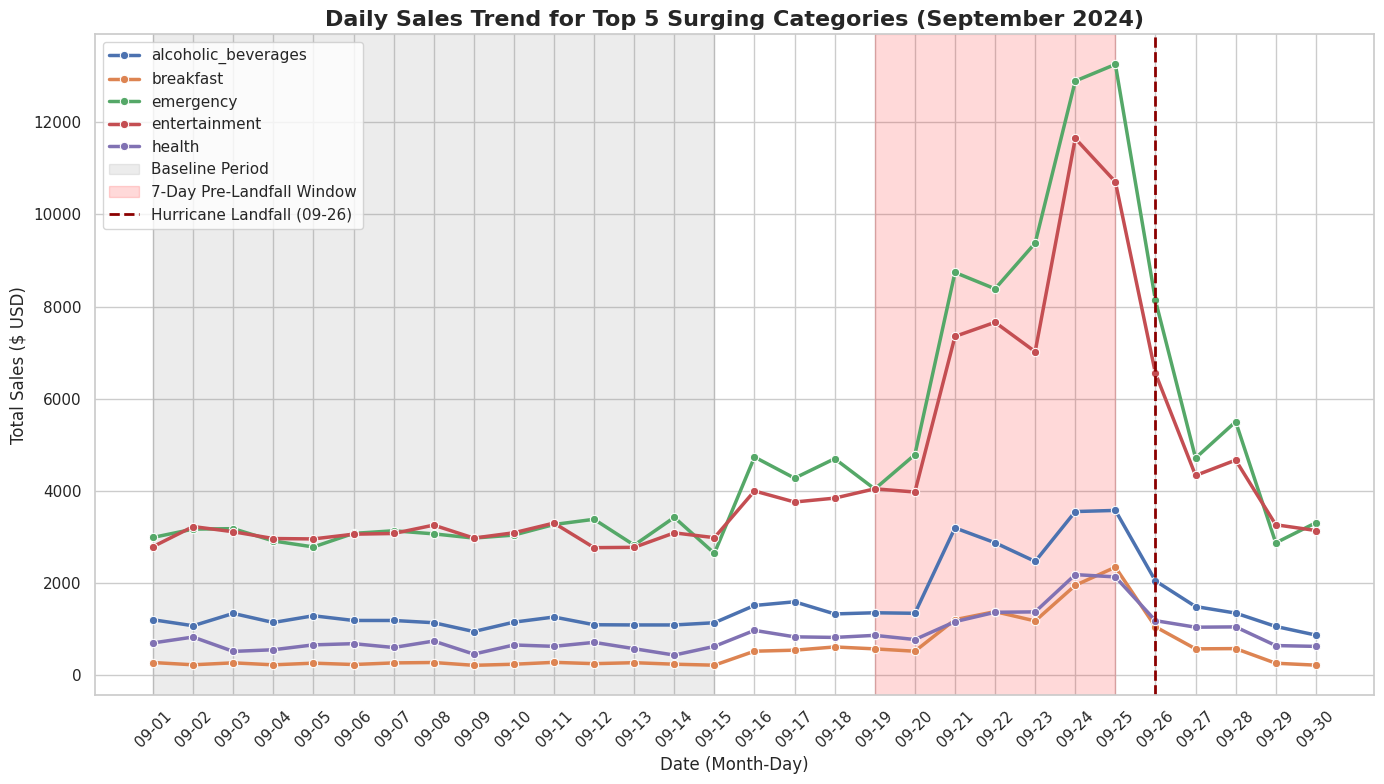

In [35]:
# 3. Plot the daily trend for the Top 5 Surging Categories
df_daily_cat = df_clean.groupby(['category', 'date'])['total_sales'].sum().reset_index()
df_daily_cat['date_str'] = df_daily_cat['date'].dt.strftime('%m-%d')

plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

# Filter for only top 5 categories
df_top5_daily = df_daily_cat[df_daily_cat['category'].isin(top_5_categories)].copy()

sns.lineplot(data=df_top5_daily, x='date_str', y='total_sales', hue='category', linewidth=2.5, marker='o')

# Highlight windows
plt.axvspan('09-01', '09-15', color='gray', alpha=0.15, label='Baseline Period')
plt.axvspan('09-19', '09-25', color='red', alpha=0.15, label='7-Day Pre-Landfall Window')
plt.axvline(x='09-26', color='darkred', linestyle='--', linewidth=2, label='Hurricane Landfall (09-26)')

plt.title('Daily Sales Trend for Top 5 Surging Categories (September 2024)', fontsize=16, fontweight='bold')
plt.xlabel('Date (Month-Day)', fontsize=12)
plt.ylabel('Total Sales ($ USD)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()

##QUESTION 1


Based on the transactions, we observed an intense spike around September 24-25 indicating that our hurricane landfall is around September 26th.

We defined our time periods as:


*   **Pre-Landfall Surge Window:** September 19, 2024 to September 25, 2024 ( 7 days prior to landfall)
*   **Baseline Window:** September 1, 2024 to September 15, 2024 ( normal historical baseline)

We compared the average daily sales revenue during these two time periods to determine which product categories experience the largest increases.

The top 5 product categories that we found were: Breafast, Emergency, Electronics, Entertainment and Alcoholic Beverages.

Breakfast had the largest increase of +415.4% with Emergency being the second-largest increase at +186.8%.

These results suggests that customers prepared for the hurricane through purchasing food, emergency supplies and products that would primarily be used while staying indoors.

The daily sales trend shows that purchasing started to increase around September 21st, as the hurricane was approaching and sales were at their highest levels about one or two days before landfall. Once, September 26 hit, sales declines, which could be due to store closures, evactation orders, or staying home due to the storm.


##QUESTION 2

In [36]:
import pandas as pd

# --- BEFORE CONSOLIDATION ---
# Let's inspect how Pop-Tarts were represented in the original, raw transactions
# We filter df_transactions where the product name or sku contains 'poptart' or 'pop-tart'
poptart_raw = df_transactions[
    df_transactions['product_name'].astype(str).str.lower().str.contains('pop-tarts strawberry|strawberry pop-tart|poptart', na=False) |
    df_transactions['sku'].astype(str).str.upper().str.contains('POPTART|PT-12|SKU#459812|PT_STRAWBERRY', na=False)
].copy()

# Standardize timestamp just for grouping by date
poptart_raw['date'] = pd.to_datetime(poptart_raw['timestamp'].astype(str).str.replace('T', ' ', regex=False).str.strip(), errors='coerce').dt.normalize()
poptart_raw = poptart_raw.dropna(subset=['date']).copy()
poptart_raw['total_sales'] = poptart_raw['quantity'] * poptart_raw['unit_price'].astype(str).str.replace('$', '', regex=False).astype(float)

daily_sales_before = poptart_raw.groupby('date').agg(
    raw_quantity_sold=('quantity', 'sum'),
    raw_sales_usd=('total_sales', 'sum')
).reset_index()

# --- AFTER CONSOLIDATION ---
# In our standardized df_clean, all Pop-Tarts are consolidated under SKU 'POPTART-STRAW'
poptart_clean = df_clean[df_clean['sku'] == 'POPTART-STRAW'].copy()
poptart_clean['total_sales'] = poptart_clean['quantity'] * poptart_clean['unit_price']

daily_sales_after = poptart_clean.groupby('date').agg(
    consolidated_quantity_sold=('quantity', 'sum'),
    consolidated_sales_usd=('total_sales', 'sum')
).reset_index()

# Merge for comparison
comparison_df = pd.merge(daily_sales_before, daily_sales_after, on='date', how='outer').sort_values('date')
comparison_df

,date,raw_quantity_sold,raw_sales_usd,consolidated_quantity_sold,consolidated_sales_usd
0,2024-09-01,39,137.05,80,280.06
1,2024-09-02,36,126.24,66,231.04
2,2024-09-03,38,132.53,79,273.44
3,2024-09-04,37,129.69,66,230.21
4,2024-09-05,52,182.44,76,266.60
5,2024-09-06,50,175.12,68,237.11
6,2024-09-07,47,164.04,78,271.87
7,2024-09-08,44,152.63,81,280.45
8,2024-09-09,36,125.04,63,219.80
9,2024-09-10,49,171.14,70,243.21


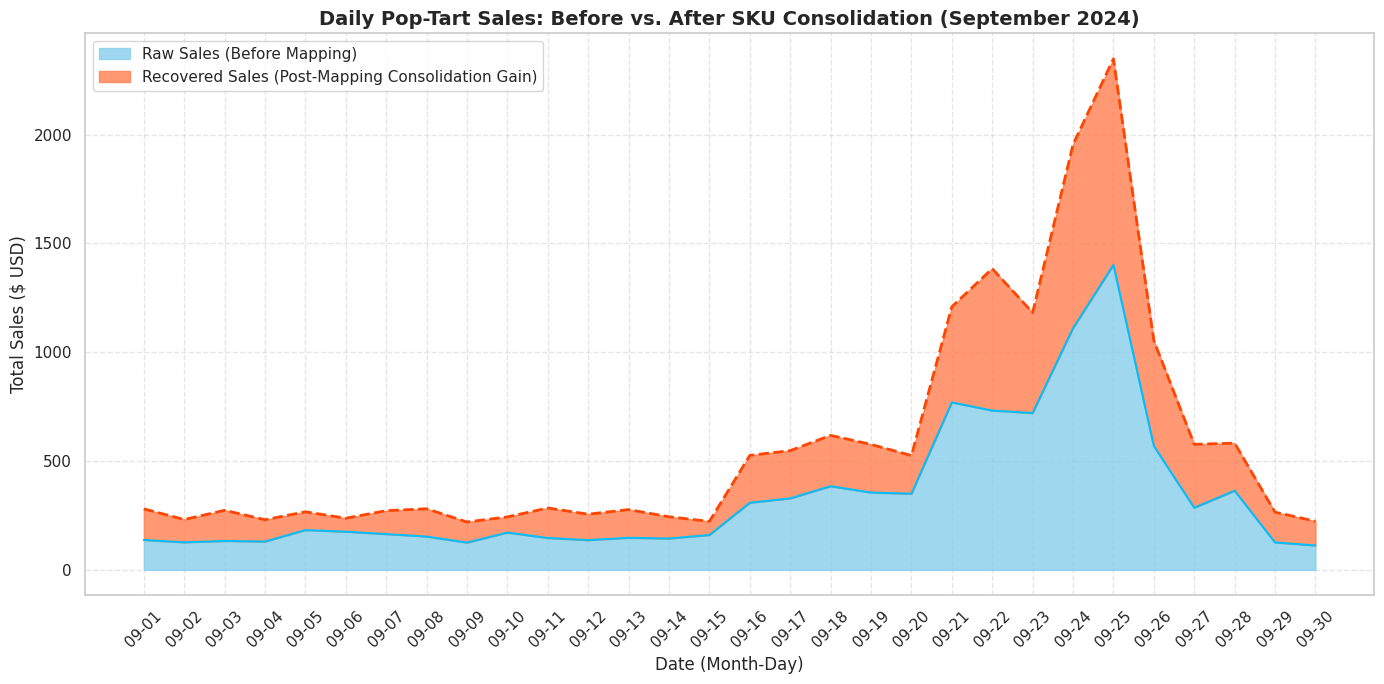

In [37]:
import matplotlib.pyplot as plt

# Ensure date is sorted and formatted properly
plot_df = comparison_df.sort_values('date').copy()
plot_df['date_str'] = plot_df['date'].dt.strftime('%m-%d')

plt.figure(figsize=(14, 7))

# Plotting raw (before) sales and the incremental gain that makes up consolidated (after) sales
# This creates a stacked representation of how much sales volume was recovered
plt.fill_between(plot_df['date_str'], 0, plot_df['raw_sales_usd'],
                 label='Raw Sales (Before Mapping)', color='skyblue', alpha=0.8)
plt.fill_between(plot_df['date_str'], plot_df['raw_sales_usd'], plot_df['consolidated_sales_usd'],
                 label='Recovered Sales (Post-Mapping Consolidation Gain)', color='coral', alpha=0.8)

# Also plot the top boundary lines for clean visualization
plt.plot(plot_df['date_str'], plot_df['raw_sales_usd'], color='deepskyblue', linewidth=1.5)
plt.plot(plot_df['date_str'], plot_df['consolidated_sales_usd'], color='orangered', linewidth=2, linestyle='--')

plt.title('Daily Pop-Tart Sales: Before vs. After SKU Consolidation (September 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Date (Month-Day)', fontsize=12)
plt.ylabel('Total Sales ($ USD)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=11)

plt.tight_layout()
plt.show()

In [20]:
# Q3: Merge daily category sales with Open-Meteo weather
# Both sides use local calendar dates; transaction timestamp timezone must be
# checked against the source case study before treating dates as equivalent.
df_sales_weather = pd.merge(
    daily_sales, df_weather,
    on=['store_id', 'date'], how='left', validate='many_to_one'
)
print('Merged rows:', len(df_sales_weather))
display(df_sales_weather.head())
weather_cols = ['wind_speed', 'precipitation', 'pressure']
print('Missing weather measurements after join:')
print(df_sales_weather[weather_cols].isna().sum())
print('Sales store IDs without an API weather match:')
print(sorted(set(daily_sales['store_id']) - set(df_weather['store_id'])))
print('Coverage (% of category-store-days with wind data):',
      round(100*df_sales_weather['wind_speed'].notna().mean(), 2))

Merged rows: 3236


,store_id,date,category,units_sold,wind_speed,precipitation,pressure
0,FL-078,2024-09-01,alcoholic_beverages,3,11.3,1.5,1014.1
1,FL-078,2024-09-01,baby_products,9,11.3,1.5,1014.1
2,FL-078,2024-09-01,breakfast,4,11.3,1.5,1014.1
3,FL-078,2024-09-01,emergency,27,11.3,1.5,1014.1
4,FL-078,2024-09-01,entertainment,16,11.3,1.5,1014.1


Missing weather measurements after join:
wind_speed       269
precipitation    269
pressure         269
dtype: int64
Sales store IDs without an API weather match:
['FL-619']
Coverage (% of category-store-days with wind data): 91.69


In [21]:
weather_vars = [
    'wind_speed',
    'precipitation',
    'pressure'
]

# Calculate correlations by category
correlations = []

for category, group in df_sales_weather.groupby('category'):

    for variable in weather_vars:

        r = group['units_sold'].corr(group[variable])

        correlations.append({
            'category': category,
            'weather_variable': variable,
            'correlation': r
        })

df_correlations = pd.DataFrame(correlations)

# Create correlation table
correlation_table = df_correlations.pivot(
    index='category',
    columns='weather_variable',
    values='correlation'
)

display(correlation_table.round(3))

weather_variable,precipitation,pressure,wind_speed
category,,,
alcoholic_beverages,-0.136,-0.169,0.137
baby_products,-0.208,-0.084,0.026
breakfast,-0.185,-0.259,0.210
emergency,-0.226,-0.257,0.208
entertainment,-0.193,-0.255,0.211
food,-0.086,0.012,0.037
grocery,-0.201,-0.167,0.097
health,-0.138,-0.206,0.182
household_essentials,-0.108,-0.202,0.200


**Q3: Correlations between weather data and sales categories; along with their meanings:**

Wind speed: Weak positive correlation with sales across all categories, especially breakfast, emergency supplies, and entertainment.

Precipitation: Negative correlations suggest customers may purchase supplies before heavy rainfall.

Barometric pressure: Generally negative correlations, indicating sales may increase as pressure decreases.

In [22]:
# Total daily sales in Florida
florida_sales = (
    daily_sales.groupby('date', as_index=False)
    ['units_sold'].sum()
)

# Average daily weather across stores
florida_weather = (
    df_weather.groupby('date', as_index=False)
    [weather_vars].mean()
)

# Merge statewide sales and weather
florida_daily = pd.merge(
    florida_sales,
    florida_weather,
    on='date',
    how='inner'
)

florida_daily = florida_daily.sort_values('date')

display(florida_daily.head())

,date,units_sold,wind_speed,precipitation,pressure
0,2024-09-01,1055,16.754545,8.990909,1013.945455
1,2024-09-02,1163,14.190909,8.218182,1013.781818
2,2024-09-03,1157,17.136364,14.372727,1015.281818
3,2024-09-04,1114,17.200000,15.854545,1017.472727
4,2024-09-05,1070,16.390909,12.118182,1016.963636


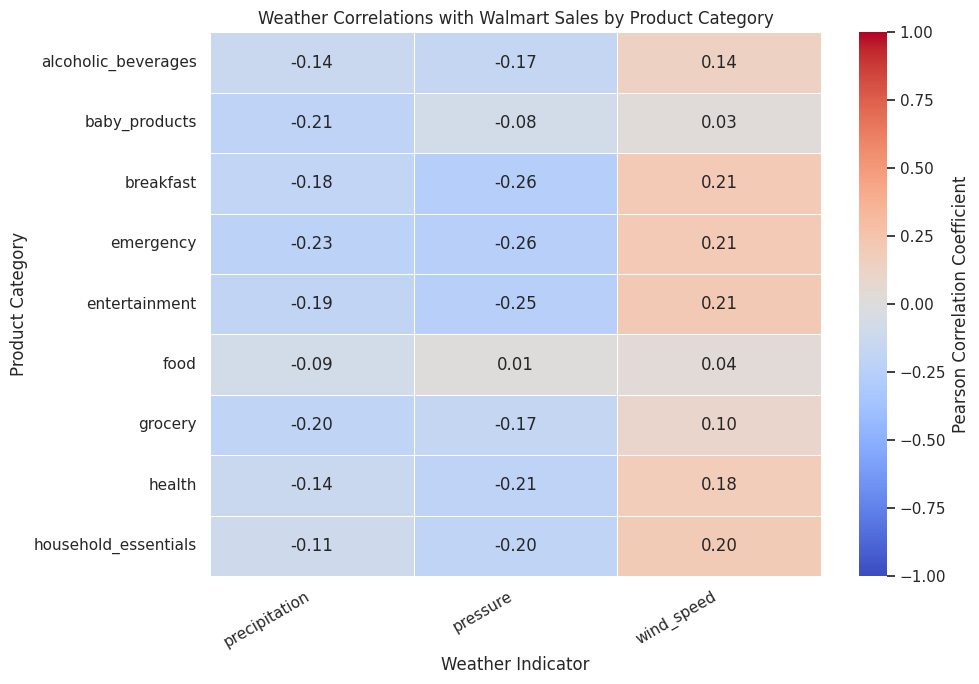

In [23]:
# Q3: Weather Correlation Heatmap

# Reshape correlation data for the heatmap
correlation_matrix = df_correlations.pivot(
    index='category',
    columns='weather_variable',
    values='correlation'
)

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)

plt.title('Weather Correlations with Walmart Sales by Product Category')
plt.xlabel('Weather Indicator')
plt.ylabel('Product Category')

plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Q3** The heatmap illustrates the Pearson correlation coefficients between daily Walmart sales volume across nine product categories and three weather indicators: precipitation, barometric pressure, and wind speed. Positive correlations indicate that sales tend to increase as the weather variable increases, while negative correlations indicate an inverse relationship. Values closer to zero represent weaker linear relationships.

**Barometric pressure** showed the strongest negative correlations with sales across most categories. Breakfast and emergency products both had correlations of approximately -0.26, followed by entertainment (-0.25) and health products (-0.21). These results suggest that lower atmospheric pressure, which can be associated with approaching storms, tended to coincide with higher sales volumes in these categories. However, all of these relationships were relatively weak.

**Wind speed** showed positive correlations across all nine categories. The strongest relationships occurred in breakfast, emergency, and entertainment products (r = 0.21), followed by household essentials (r = 0.20) and health products (r = 0.18). This suggests that higher wind speeds were associated with slightly higher sales volumes, potentially reflecting increased purchasing activity during worsening weather conditions.

**Precipitation** was negatively correlated with sales across all categories. Emergency products showed the strongest negative correlation (-0.23), followed by baby products (-0.21) and grocery products (-0.20). These results suggest that higher rainfall was generally associated with lower same-day purchasing activity. One possible explanation is that customers purchased supplies before heavy rainfall began, although additional analysis would be needed to confirm this.

The food category showed the weakest overall relationships with weather conditions, including precipitation (-0.09), pressure (0.01), and wind speed (0.04). This suggests that general food sales were less closely associated with daily weather variation than categories such as breakfast and emergency supplies.

Overall, the results suggest that barometric pressure and wind speed were more consistently associated with changes in Walmart sales than precipitation. However, all observed correlations were weak, with absolute values below 0.30.

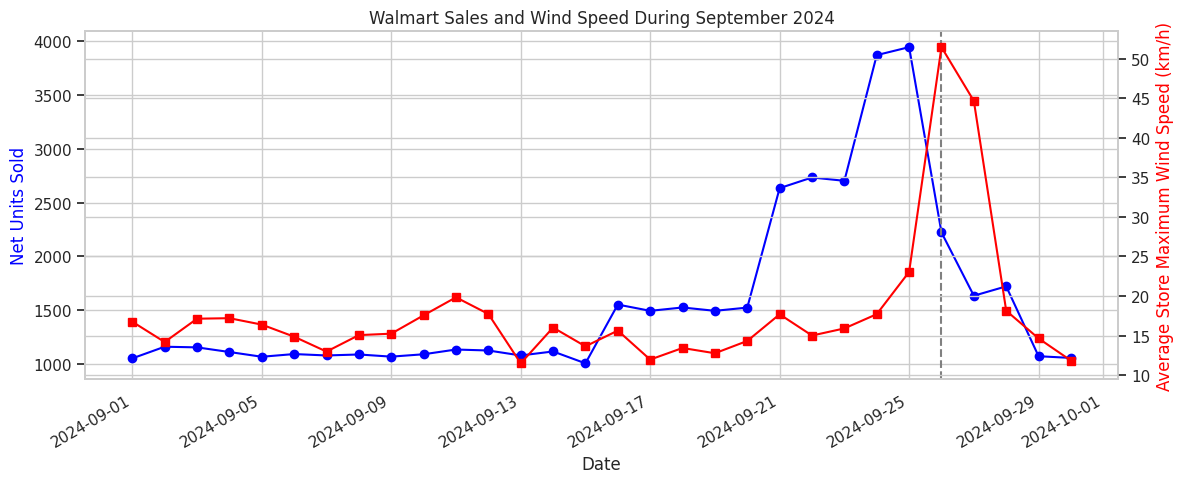

In [24]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Plot sales volume
ax1.plot(
    florida_daily['date'],
    florida_daily['units_sold'],
    color='blue',
    marker='o',
    label='Sales Volume'
)

ax1.set_xlabel('Date')
ax1.set_ylabel('Net Units Sold', color='blue')

# Plot wind speed
ax2 = ax1.twinx()

ax2.plot(
    florida_daily['date'],
    florida_daily['wind_speed'],
    color='red',
    marker='s',
    label='Wind Speed'
)

ax2.set_ylabel('Average Store Maximum Wind Speed (km/h)', color='red')

# Hurricane Helene landfall
ax1.axvline(
    pd.Timestamp('2024-09-26'),
    color='gray',
    linestyle='--',
    label='Hurricane Landfall'
)

plt.title('Walmart Sales and Wind Speed During September 2024')

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Q3** September 1–20
Sales remained relatively stable at around 1,000–1,500 units per day, with minor wind speed fluctuations.
September 21–25
Sales increased significantly, reaching nearly 4,000 units as Hurricane Helene approached.
September 26 (Landfall)
Wind speeds peaked at approximately 52 km/h, while sales dropped sharply.
After landfall: Both wind speeds and sales declined toward normal levels.
Overall
The graph suggests customers purchased supplies before the strongest winds arrived, with sales peaking approximately one day before landfall.

In [25]:
lag_results = []

for variable in weather_vars:

    for lag in range(0, 8):

        future_weather = florida_daily[variable].shift(-lag)

        correlation = florida_daily['units_sold'].corr(
            future_weather
        )

        lag_results.append({
            'weather_variable': variable,
            'days_ahead': lag,
            'correlation': correlation
        })

df_lag = pd.DataFrame(lag_results)

display(df_lag.round(3))

,weather_variable,days_ahead,correlation
0,wind_speed,0,0.254
1,wind_speed,1,0.611
2,wind_speed,2,0.809
3,wind_speed,3,0.616
4,wind_speed,4,0.425
5,wind_speed,5,0.339
6,wind_speed,6,0.186
7,wind_speed,7,0.065
8,precipitation,0,-0.375
9,precipitation,1,-0.143


**Q3**
Wind speed: Strongest positive correlation (0.809) at a 2-day lead, suggesting sales increased approximately two days before stronger winds.

Precipitation: Weak negative correlations across all lags, with the strongest at 0 days (−0.375).

Barometric pressure: Strongest negative correlation (−0.728) at a 2-day lead, suggesting sales increased before atmospheric pressure dropped.

Overall: Purchasing spikes appeared to precede worsening weather by approximately 2 days, suggesting customers were preparing for Hurricane Helene in advance.

Limitation: These correlations show timing relationships, not proof that weather caused the purchasing spikes.

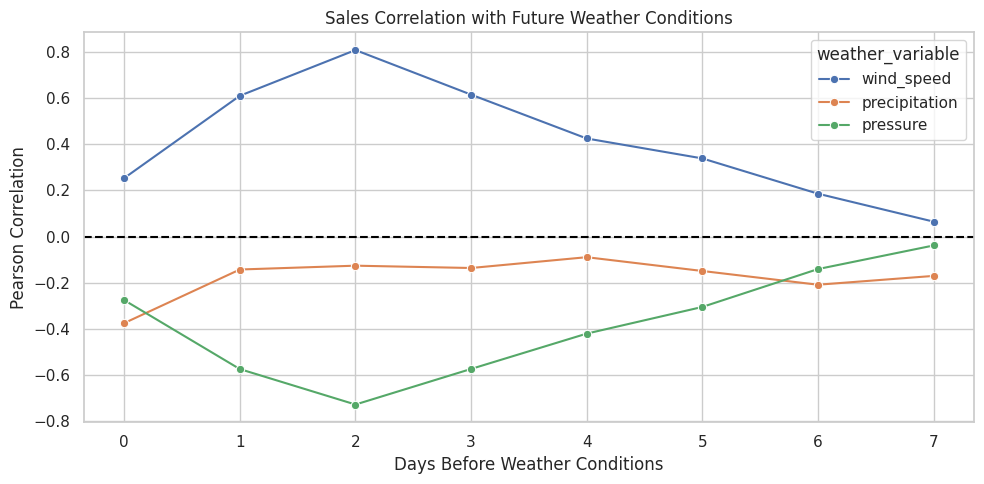

In [26]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=df_lag,
    x='days_ahead',
    y='correlation',
    hue='weather_variable',
    marker='o'
)

plt.axhline(0, color='black', linestyle='--')

plt.title('Sales Correlation with Future Weather Conditions')
plt.xlabel('Days Before Weather Conditions')
plt.ylabel('Pearson Correlation')

plt.tight_layout()
plt.show()

**Q3**
The strongest correlations occurred at a 2-day lag, suggesting Walmart sales increased approximately two days before stronger winds and lower barometric pressure. This indicates customers may have been purchasing supplies in preparation for Hurricane Helene.

In [27]:
# Strongest weather relationships
strongest = df_correlations.copy()

strongest['absolute_correlation'] = (
    strongest['correlation'].abs()
)

strongest = strongest.sort_values(
    'absolute_correlation',
    ascending=False
)

print("Strongest category-weather correlations:")
display(strongest.head(10))

# Strongest wind-speed lag
wind_lags = df_lag[
    df_lag['weather_variable'] == 'wind_speed'
].dropna()

best_lag = wind_lags.loc[
    wind_lags['correlation'].abs().idxmax()
]

print("Strongest wind speed lag:")
print(best_lag)

Strongest category-weather correlations:


,category,weather_variable,correlation,absolute_correlation
8,breakfast,pressure,-0.259024,0.259024
11,emergency,pressure,-0.256513,0.256513
14,entertainment,pressure,-0.254610,0.254610
10,emergency,precipitation,-0.226252,0.226252
12,entertainment,wind_speed,0.210970,0.210970
6,breakfast,wind_speed,0.210213,0.210213
9,emergency,wind_speed,0.208500,0.208500
4,baby_products,precipitation,-0.208088,0.208088
23,health,pressure,-0.205902,0.205902
26,household_essentials,pressure,-0.202307,0.202307


Strongest wind speed lag:
weather_variable    wind_speed
days_ahead                   2
correlation           0.808754
Name: 2, dtype: object


**QUESTION 4**

In [28]:
# Q4: Combine total daily sales with geographic store records
store_daily = (daily_sales.groupby(['store_id','date'],as_index=False)['units_sold'].sum())
store_info = df_clean_store[['store_id','city','latitude','longitude']].copy()
if 'region' in df_clean_store.columns:
    store_info['region'] = df_clean_store['region']
store_info['latitude'] = pd.to_numeric(store_info['latitude'], errors='coerce')
store_info['longitude'] = pd.to_numeric(store_info['longitude'], errors='coerce')
store_info = store_info.drop_duplicates('store_id')
store_daily = store_daily.merge(store_info, on='store_id', how='left', validate='many_to_one')
print('Distinct stores in transactions:',store_daily['store_id'].nunique())
print('Missing coordinates:',store_daily[['latitude','longitude']].isna().sum().to_dict())
display(store_daily.head())

Distinct stores in transactions: 12
Missing coordinates: {'latitude': 30, 'longitude': 30}


,store_id,date,units_sold,city,latitude,longitude,region
0,FL-078,2024-09-01,76,Gainesville,29.6516,-82.3248,North
1,FL-078,2024-09-02,103,Gainesville,29.6516,-82.3248,North
2,FL-078,2024-09-03,101,Gainesville,29.6516,-82.3248,North
3,FL-078,2024-09-04,84,Gainesville,29.6516,-82.3248,North
4,FL-078,2024-09-05,90,Gainesville,29.6516,-82.3248,North


**Q4**
To investigate geographic differences in purchasing behavior, daily transaction records were combined with Walmart store location data using the store ID as the common identifier. This merge allowed each store's sales volume to be associated with its city, latitude, and longitude. Missing coordinates and duplicate store IDs were checked to ensure accurate geographic comparisons. Sales were aggregated by store and date to identify location-specific purchasing patterns before Hurricane Helene.

Missing store-day observations: 0
Store-level baseline/surge comparison:


,store_id,baseline_avg,baseline_days,surge_avg,surge_days,city,latitude,longitude,region,surge_pct
6,FL-330,95.89,18,235.14,7,Miami,25.76,-80.19,South,145.22
1,FL-105,97.17,18,231.29,7,Tampa,27.95,-82.46,West,138.03
10,FL-619,93.56,18,222.43,7,Tallahassee,NaN,NaN,Panhandle,137.75
5,FL-302,102.11,18,239.29,7,Lakeland,28.04,-81.95,Central,134.34
11,FL-710,97.72,18,226.43,7,Pensacola,30.42,-87.22,Panhandle,131.71
7,FL-412,95.61,18,221.43,7,Jacksonville,30.33,-81.66,North,131.59
2,FL-156,98.78,18,228.57,7,Daytona Beach,29.21,-81.02,East,131.40
8,FL-445,101.00,18,231.43,7,St. Petersburg,27.77,-82.64,West,129.14
9,FL-501,96.50,18,219.43,7,Fort Myers,26.64,-81.87,West,127.39
4,FL-287,96.28,18,218.71,7,Kissimmee,28.29,-81.41,Central,127.17


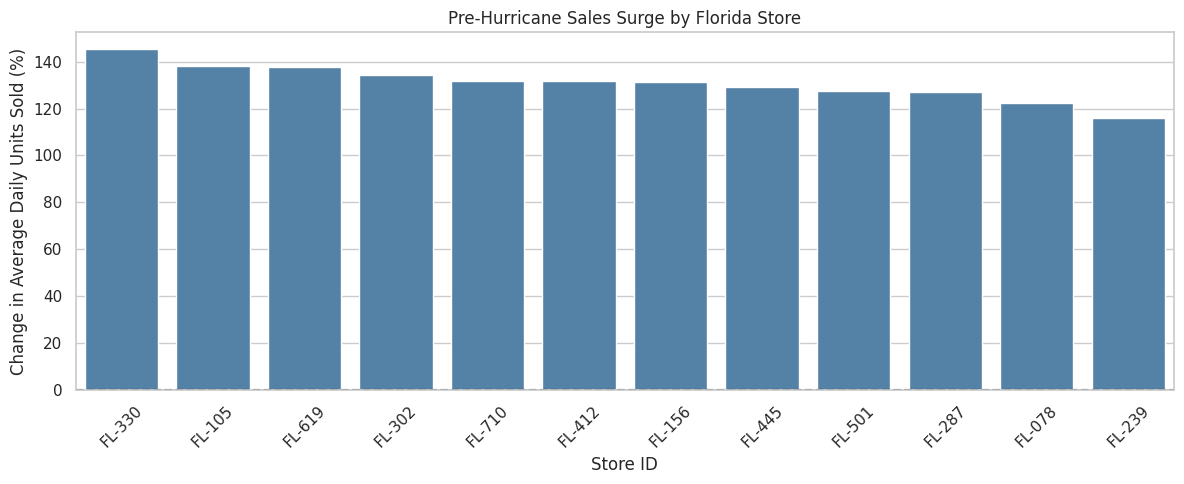

In [29]:
# Q4: Baseline vs. pre-landfall average daily units, by store
baseline_start, baseline_end = pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-18')
surge_start, surge_end = pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25')
# Include missing days explicitly; don't mistake absent transaction records for zero sales.
idx = pd.MultiIndex.from_product([store_daily['store_id'].unique(),
                                 pd.date_range(baseline_start,surge_end)],names=['store_id','date'])
complete = store_daily.set_index(['store_id','date'])[['units_sold']].reindex(idx).reset_index()
print('Missing store-day observations:', complete['units_sold'].isna().sum())
base = complete[complete['date'].between(baseline_start,baseline_end)].groupby('store_id')['units_sold'].agg(['mean','count']).rename(columns={'mean':'baseline_avg','count':'baseline_days'})
surge = complete[complete['date'].between(surge_start,surge_end)].groupby('store_id')['units_sold'].agg(['mean','count']).rename(columns={'mean':'surge_avg','count':'surge_days'})
store_comparison = base.join(surge).reset_index().merge(store_info,on='store_id',how='left')
store_comparison['surge_pct'] = np.where(store_comparison['baseline_avg']>0,100*(store_comparison['surge_avg']/store_comparison['baseline_avg']-1),np.nan)
print('Store-level baseline/surge comparison:')
display(store_comparison.sort_values('surge_pct',ascending=False).round(2))
plt.figure(figsize=(12,5))
sns.barplot(data=store_comparison.sort_values('surge_pct',ascending=False), x='store_id',y='surge_pct',color='steelblue')
plt.axhline(0,color='black',linestyle='--');plt.title('Pre-Hurricane Sales Surge by Florida Store')
plt.xlabel('Store ID');plt.ylabel('Change in Average Daily Units Sold (%)');plt.xticks(rotation=45)
plt.tight_layout();plt.show()

**Q4**
Average daily sales were compared between the baseline period (September 1–18, 2024) and the seven days preceding Hurricane Helene's landfall (September 19–25, 2024). Percentage changes were calculated to account for differences in typical sales volume across stores.

All 12 stores experienced substantial increases in sales, ranging from approximately 115.83% to 145.22%. The largest surge occurred at FL-330 in Miami, with a 145.22% increase, followed by FL-105 in Tampa (138.03%) and FL-619 in Tallahassee (137.75%). The smallest increase occurred at FL-239 in Orlando (115.83%).

These findings demonstrate that although hurricane-related purchasing increased across all locations, the magnitude of the increases varied.

In [30]:
# Find the top product by surge multiple
baseline = df_clean[
    df_clean['date'].between('2024-09-01', '2024-09-18')
]
surge = df_clean[
    df_clean['date'].between('2024-09-19', '2024-09-25')
]
# Calculate average daily units sold by standardized SKU
baseline_sales = baseline.groupby('sku')['quantity'].sum() / 18
surge_sales = surge.groupby('sku')['quantity'].sum() / 7

results = pd.concat(
    [baseline_sales.rename('baseline_daily_avg'),
     surge_sales.rename('surge_daily_avg')],
    axis=1
).fillna(0)

# Calculate surge multiple
results = results[results['baseline_daily_avg'] > 0].copy()

results['surge_multiple'] = (
    results['surge_daily_avg'] /
    results['baseline_daily_avg']
)
# Find highest surge multiple
top = results.sort_values(
    'surge_multiple', ascending=False
).iloc[0]

top_sku = results['surge_multiple'].idxmax()

print(f"Top product: {top_sku}")
print(f"Surge multiple: {top['surge_multiple']:.2f}x")
print("Baseline window: September 1–18, 2024")
print("Surge window: September 19–25, 2024")

Top product: POPTART-STRAW
Surge multiple: 4.28x
Baseline window: September 1–18, 2024
Surge window: September 19–25, 2024


,store_id,city,surge_pct,first_spike_date,peak_date,days_before_landfall
10,FL-619,Tallahassee,137.750254,2024-09-20,2024-09-24,6
0,FL-078,Gainesville,122.310757,2024-09-21,2024-09-25,5
1,FL-105,Tampa,138.029895,2024-09-21,2024-09-25,5
2,FL-156,Daytona Beach,131.399646,2024-09-21,2024-09-24,5
3,FL-239,Orlando,115.834768,2024-09-21,2024-09-24,5
4,FL-287,Kissimmee,127.170060,2024-09-21,2024-09-25,5
5,FL-302,Lakeland,134.338567,2024-09-21,2024-09-25,5
6,FL-330,Miami,145.224301,2024-09-21,2024-09-24,5
7,FL-412,Jacksonville,131.592928,2024-09-21,2024-09-25,5
8,FL-445,St. Petersburg,129.137199,2024-09-21,2024-09-24,5


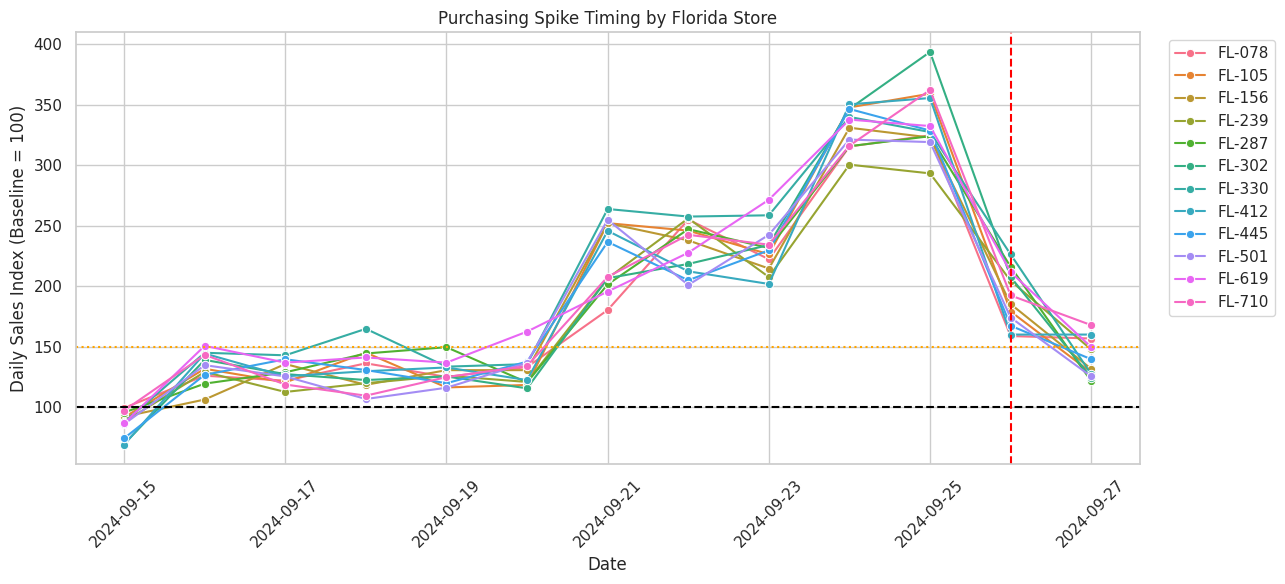

In [31]:
# Q4: Find first qualifying surge date and peak sales date
baseline_lookup = store_comparison[['store_id','baseline_avg']]
store_timing_daily = store_daily.merge(baseline_lookup,on='store_id',how='left')
store_timing_daily['index_pct'] = np.where(store_timing_daily['baseline_avg']>0,
                    100*store_timing_daily['units_sold']/store_timing_daily['baseline_avg'],np.nan)
pre = store_timing_daily[store_timing_daily['date'].between(surge_start,surge_end)].copy()
first = pre[pre['index_pct']>=150].groupby('store_id')['date'].min().rename('first_spike_date').reset_index()
peak_idx = pre.groupby('store_id')['units_sold'].idxmax()
peak = pre.loc[peak_idx,['store_id','date','units_sold']].rename(columns={'date':'peak_date','units_sold':'peak_units'})
store_timing = store_comparison.merge(first,on='store_id',how='left').merge(peak,on='store_id',how='left')
store_timing['days_before_landfall'] = (pd.Timestamp('2024-09-26')-store_timing['first_spike_date']).dt.days
display(store_timing[['store_id','city','surge_pct','first_spike_date','peak_date','days_before_landfall']].sort_values('first_spike_date'))
plt.figure(figsize=(13,6))
sns.lineplot(data=store_timing_daily[store_timing_daily['date'].between('2024-09-15','2024-09-27')],x='date',y='index_pct',hue='store_id',marker='o',errorbar=None)
plt.axhline(100,color='black',linestyle='--');plt.axhline(150,color='orange',linestyle=':')
plt.axvline(pd.Timestamp('2024-09-26'),color='red',linestyle='--')
plt.title('Purchasing Spike Timing by Florida Store');plt.ylabel('Daily Sales Index (Baseline = 100)');plt.xlabel('Date')
plt.xticks(rotation=45);plt.legend(bbox_to_anchor=(1.02,1),loc='upper left');plt.tight_layout();plt.show()

**Q4**
The graph showed that sales began increasing across multiple stores before Hurricane Helene's landfall on September 26, 2024. FL-619 in Tallahassee reached the spike threshold on September 20, while FL-330 in Miami, FL-105 in Tampa, FL-239 in Orlando, and FL-078 in Gainesville reached the threshold on September 21.

The time-series visualization shows that purchasing intensified substantially between September 21 and September 25, with most stores reaching their highest observed sales on September 24 or 25. Peak sales indices approached 300–400 for several locations, indicating sales volumes approximately three to four times their baseline averages.

Although some stores experienced earlier spikes, the overall timing was relatively consistent, suggesting that hurricane preparation occurred across multiple locations within a similar timeframe.

Correlation: distance to Perry vicinity vs. sales surge: 0.56


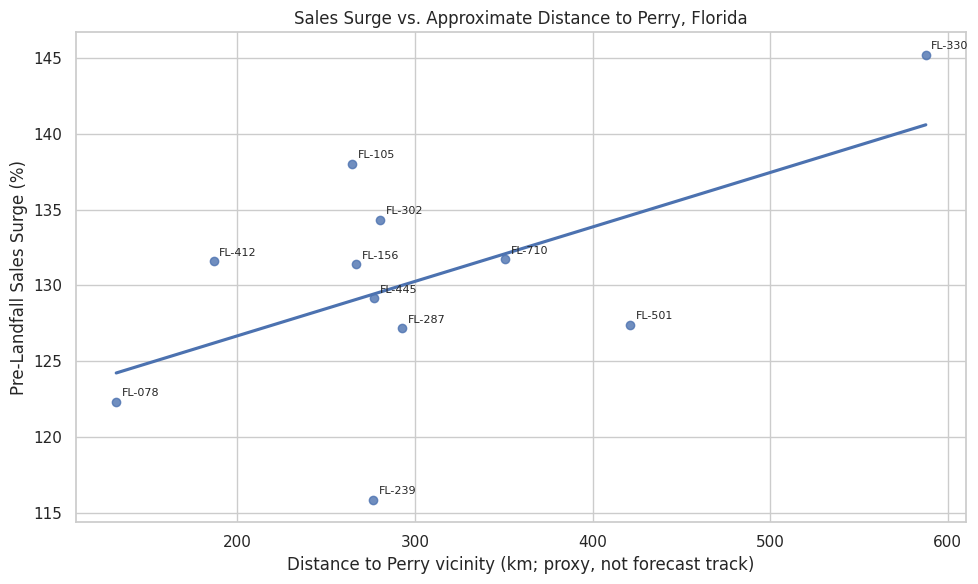

Correlation cannot be calculated because there are too few observations or insufficient variation in spike timing.


,store_id,city,distance_to_perry_km,first_spike_date,days_before_landfall
0,FL-078,Gainesville,131.79,2024-09-21,5
7,FL-412,Jacksonville,186.59,2024-09-21,5
1,FL-105,Tampa,264.58,2024-09-21,5
2,FL-156,Daytona Beach,267.01,2024-09-21,5
3,FL-239,Orlando,276.44,2024-09-21,5
8,FL-445,St. Petersburg,276.88,2024-09-21,5
5,FL-302,Lakeland,280.24,2024-09-21,5
4,FL-287,Kissimmee,292.79,2024-09-21,5
11,FL-710,Pensacola,350.71,2024-09-21,5
9,FL-501,Fort Myers,421.21,2024-09-21,5


,store_id,city,distance_to_perry_km,surge_pct,days_before_landfall
0,FL-078,Gainesville,131.79,122.31,5
7,FL-412,Jacksonville,186.59,131.59,5
1,FL-105,Tampa,264.58,138.03,5
2,FL-156,Daytona Beach,267.01,131.40,5
3,FL-239,Orlando,276.44,115.83,5
8,FL-445,St. Petersburg,276.88,129.14,5
5,FL-302,Lakeland,280.24,134.34,5
4,FL-287,Kissimmee,292.79,127.17,5
11,FL-710,Pensacola,350.71,131.71,5
9,FL-501,Fort Myers,421.21,127.39,5


In [32]:
# Q4: Geography — approximate distance to landfall vicinity near Perry, FL
# This is a fixed landfall-proximity proxy, NOT an archived forecast path.
# Approximate Perry, Florida coordinates: 30.1174 N, 83.5818 W.
def haversine_km(lat1,lon1,lat2,lon2):
    r=6371.0
    p1,p2=np.radians(lat1),np.radians(lat2)
    dp=np.radians(lat2-lat1); dl=np.radians(lon2-lon1)
    a=np.sin(dp/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2*r*np.arcsin(np.sqrt(a))
store_timing['distance_to_perry_km']=haversine_km(store_timing['latitude'],store_timing['longitude'],30.1174,-83.5818)
valid_geo=store_timing.dropna(subset=['distance_to_perry_km','surge_pct'])
r_distance=valid_geo['distance_to_perry_km'].corr(valid_geo['surge_pct'])
print('Correlation: distance to Perry vicinity vs. sales surge:',round(r_distance,3))
plt.figure(figsize=(10,6))
sns.regplot(data=valid_geo,x='distance_to_perry_km',y='surge_pct',ci=None)
for _,row in valid_geo.iterrows():
    plt.annotate(row['store_id'],(row['distance_to_perry_km'],row['surge_pct']),xytext=(4,4),textcoords='offset points',fontsize=8)
plt.title('Sales Surge vs. Approximate Distance to Perry, Florida')
plt.xlabel('Distance to Perry vicinity (km; proxy, not forecast track)');plt.ylabel('Pre-Landfall Sales Surge (%)')
plt.tight_layout();plt.show()

# Compare geographic distance with purchasing spike timing
valid_timing = store_timing.dropna(
    subset=['distance_to_perry_km', 'days_before_landfall']
).copy()

if (
    len(valid_timing) >= 2
    and valid_timing['distance_to_perry_km'].nunique() > 1
    and valid_timing['days_before_landfall'].nunique() > 1
):
    r_timing = valid_timing[
        'distance_to_perry_km'
    ].corr(valid_timing['days_before_landfall'])

    print(
        "Correlation: distance vs. spike timing:",
        round(r_timing, 3)
    )
else:
    print(
        "Correlation cannot be calculated because "
        "there are too few observations or insufficient "
        "variation in spike timing."
    )

# Show store-level timing for interpretation
display(
    valid_timing[
        ['store_id', 'city', 'distance_to_perry_km',
         'first_spike_date', 'days_before_landfall']
    ].sort_values('distance_to_perry_km').round(2)
)

display(store_timing[['store_id','city','distance_to_perry_km','surge_pct','days_before_landfall']].sort_values('distance_to_perry_km').round(2))

**Q4**
TTo determine whether geographic proximity influenced purchasing timing, each Walmart store's distance from the approximate landfall vicinity near Perry, Florida, was compared with the date of its first qualifying sales spike. A purchasing spike was defined as a daily sales increase of at least 50% above the store's baseline average.

Of the 12 stores analyzed, 11 experienced their first qualifying purchasing spike on September 21, 2024, five days before Hurricane Helene's landfall. The remaining store, FL-619 in Tallahassee, experienced its first spike on September 20, six days before landfall.

The initial Pearson correlation calculation returned an undefined value (NaN) because Tallahassee lacked geographic coordinates and was excluded from the comparison. All remaining stores had identical spike timing, leaving no variation in the timing variable.

These results demonstrate that purchasing spikes occurred almost simultaneously across Florida stores, despite substantial geographic differences. For example, Gainesville was approximately 131.79 km from Perry, while Miami was approximately 587.68 km away, yet both stores experienced their first qualifying spike on September 21.

This suggests that purchasing behavior may have been influenced by widespread hurricane awareness and preparation rather than geographic proximity alone. However, further analysis is necessary to establish whether distance significantly influenced purchasing timing.

In [33]:
# Q4: Flag unusually high or low surges (1.5 x IQR rule)
s=store_timing['surge_pct'].dropna(); q1,q3=s.quantile([.25,.75]); iqr=q3-q1
low, high=q1-1.5*iqr, q3+1.5*iqr
store_timing['iqr_outlier']=(store_timing['surge_pct']<low)|(store_timing['surge_pct']>high)
print('IQR thresholds:',round(low,2),round(high,2))
print('Flagged stores:')
display(store_timing.loc[store_timing['iqr_outlier'],['store_id','city','surge_pct','distance_to_perry_km']])
print('Highest and lowest surge stores (even if no IQR outlier):')
display(pd.concat([store_timing.nlargest(3,'surge_pct'),store_timing.nsmallest(3,'surge_pct')]).drop_duplicates('store_id')[['store_id','city','surge_pct','first_spike_date','distance_to_perry_km']])
if 'region' in store_timing.columns:
    print('Mean store-level surge by geographic region:')
    display(store_timing.groupby('region',dropna=False)['surge_pct'].agg(['mean','count']).round(2))
# Add cleaned regions to store comparison
store_comparison = store_comparison.drop(
    columns=['region'], errors='ignore'
)

store_comparison = store_comparison.merge(
    df_clean_store[['store_id', 'region']].drop_duplicates('store_id'),
    on='store_id',
    how='left'
)

IQR thresholds: 115.54 146.98
Flagged stores:


,store_id,city,surge_pct,distance_to_perry_km


Highest and lowest surge stores (even if no IQR outlier):


,store_id,city,surge_pct,first_spike_date,distance_to_perry_km
6,FL-330,Miami,145.224301,2024-09-21,587.682026
1,FL-105,Tampa,138.029895,2024-09-21,264.578980
10,FL-619,Tallahassee,137.750254,2024-09-20,NaN
3,FL-239,Orlando,115.834768,2024-09-21,276.438026
0,FL-078,Gainesville,122.310757,2024-09-21,131.789996
4,FL-287,Kissimmee,127.170060,2024-09-21,292.785202


Mean store-level surge by geographic region:


,mean,count
region,,
Panhandle,137.75,1
Central,125.78,3
East,131.40,1
North,126.95,2
Panhandle,131.71,1
South,145.22,1
West,131.52,3


**Q4**
The interquartile range (IQR) method was used to identify stores with unusually high or low sales surge percentages. The calculated lower threshold was 115.54%, while the upper threshold was 146.98%. Stores outside these boundaries would be classified as statistical outliers.

No stores were identified as statistical outliers because all observed sales increases fell within these thresholds. However, some locations exhibited noticeably different purchasing patterns.

FL-330 in Miami experienced the highest surge at 145.22%, approaching the upper threshold. Meanwhile, FL-239 in Orlando experienced the smallest increase at 115.83%, just above the lower threshold.

Although neither store qualifies as a statistical outlier, these differences highlight variation in purchasing behavior across locations. The absence of statistical outliers suggests that the observed increases were within the overall range of variation across stores, although the small sample size limits the reliability of outlier detection.